# Esperimento portfolio sintetico single-pass

Questo notebook analizza artifact gia` pubblicati dal runner interno. Non costruisce il problema e non esegue la pipeline QReduce.

Prima di eseguirlo, creare un run dal repository con:

```bash
poetry run python -m qreduce.experiments.portfolio --run-id run-001
```

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from qreduce.experiments.portfolio import load_synthetic_portfolio_analysis
from qreduce.notebook_plots import plot_correlation_matrix, plot_reduction_graph

repository_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "pyproject.toml").is_file()),
    None,
)
if repository_root is None:
    raise RuntimeError("Run this notebook from inside the QReduce repository.")

run_directory = repository_root / "outputs/synthetic-portfolio-single-pass/run-001"
analysis = load_synthetic_portfolio_analysis(run_directory)
artifacts = analysis.artifacts
result = artifacts.result

In [3]:
display(pd.Series(artifacts.manifest, name="value").to_frame())
display(pd.DataFrame(analysis.node_rows()))
display(pd.DataFrame(analysis.edge_rows()))

,value
artifact_schema_version,1.0
config_hash,dfa2648121ff1e3f1ddb7bc8094f6d86d5dff49972efd0...
created_at,2026-11-11T10:18:34.970491Z
experiment_id,synthetic-portfolio-single-pass
files,{'canonical_mwis_problem.json': '24c778bb83280...
producer_version,0.1.0
run_id,run-001
run_status,success


,asset,retention_score
0,asset-a,0.9
1,asset-b,0.7
2,asset-c,0.8
3,asset-d,0.6
4,asset-e,0.5


,source,target,reason
0,asset-a,asset-b,abs_correlation=0.4 >= threshold=0.25
1,asset-b,asset-c,abs_correlation=0.3 >= threshold=0.25
2,asset-c,asset-d,abs_correlation=0.35 >= threshold=0.25
3,asset-d,asset-e,abs_correlation=0.3 >= threshold=0.25


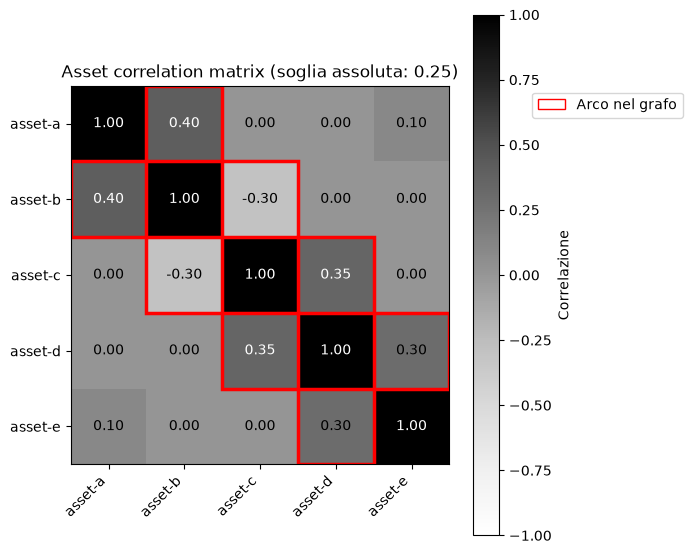

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plot_correlation_matrix(
    analysis.asset_ids,
    analysis.correlation,
    analysis.graph,
    analysis.correlation_threshold,
)
plt.show()

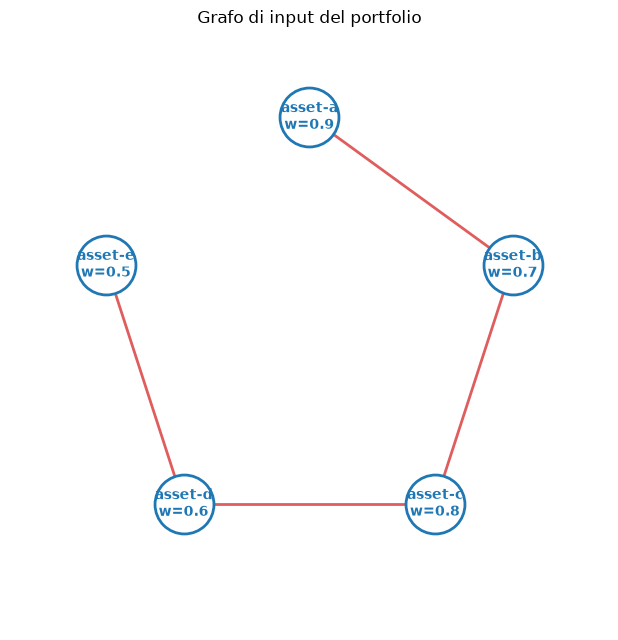

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plot_reduction_graph(analysis.graph, title="Grafo di input del portfolio")
plt.show()

In [6]:
display(pd.Series(result["run_result"], name="value").to_frame())
display(pd.Series(result["metrics"], name="value").to_frame())

,value
adoption_status,adopted
classical_solver_status,optimal
config_hash,dfa2648121ff1e3f1ddb7bc8094f6d86d5dff49972efd0...
diagnostic_message,None
input_hash,None
policy_hash,None
postcheck_status,passed
round_results,[]
run_id,run-001
run_status,success


,value
best_bound,None
candidate_domain_size,3
classical_runtime_seconds,0.016526
classical_solver_claimed_feasible,True
end_to_end_runtime_seconds,0.038607
mis_backend_family,classical_heuristic
mis_backend_id,greedy_mis
mis_compilation_runtime_seconds,0.000006
mis_device_id,None
mis_execution_mode,local


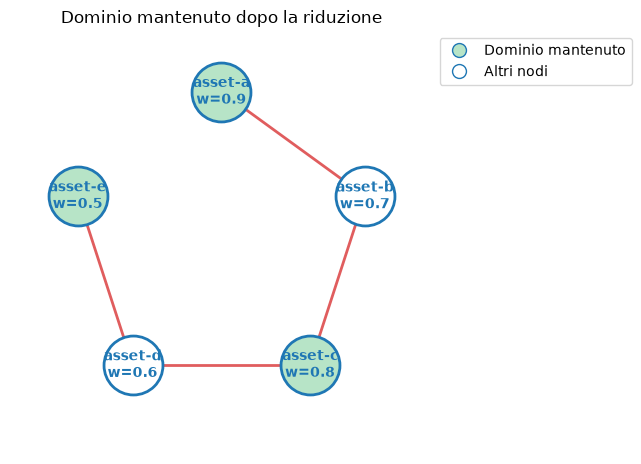

,asset,retained
0,asset-a,True
1,asset-b,False
2,asset-c,True
3,asset-d,False
4,asset-e,True


{'entries': [{'item_id': 'asset-b',
   'reason': 'heuristic_candidate_domain_exclusion',
   'variable_values': {'delta__asset-b': 0.0, 'x__asset-b': 0.0}},
  {'item_id': 'asset-d',
   'reason': 'heuristic_candidate_domain_exclusion',
   'variable_values': {'delta__asset-d': 0.0, 'x__asset-d': 0.0}}],
 'excluded_item_ids': ['asset-b', 'asset-d'],
 'origin': 'heuristic_candidate_domain',
 'provenance': {'graph_policy_id': 'synthetic-portfolio-policy',
  'graph_policy_version': '1',
  'optimality_preservation_claim': 'none'},
 'retained_item_ids': ['asset-a', 'asset-c', 'asset-e']}

In [7]:
fig, ax = plot_reduction_graph(
    analysis.graph,
    analysis.retained_item_ids,
    highlighted_label="Dominio mantenuto",
    title="Dominio mantenuto dopo la riduzione",
)
plt.show()

display(pd.DataFrame(analysis.domain_rows()))
display(result["fixing_manifest"])

In [8]:
display(pd.DataFrame(result["selected_mis_samples"]))
display(result["classical_result"])
display(result["postcheck_result"])

,backend_reported_score,backend_reported_score_kind,canonical_ising_energy,canonical_qubo_energy,delta,effective_compilation_parameters,effective_execution_parameters,execution_runtime_seconds,is_independent_set,node_order,num_selected,num_violated_edges,occurrence_count,raw_backend_metadata,raw_sample_id,selection_weight,source_backend_id,source_provider_id,source_raw_sample_ids,violated_edges
0,None,unavailable,-2.2,-2.2,"[1, 0, 1, 0, 1]",{},{},0.000022,True,"[asset-a, asset-b, asset-c, asset-d, asset-e]",3,0,1,{'algorithm': 'seeded_greedy_independent_set'},run-001:round:0:local-greedy:sample:0000,2.2,greedy_mis,local,[run-001:round:0:local-greedy:sample:0000],[]


{'best_bound': None,
 'classical_solver_status': 'optimal',
 'constraint_count': 15,
 'diagnostic_message': None,
 'effective_solver_id': 'cplex',
 'effective_solver_parameters': {'random_seed': 7,
  'threads': 1,
  'time_limit_seconds': 10.0},
 'gap': 0.0,
 'is_optimal': True,
 'is_time_limited': False,
 'model_export_path': None,
 'objective_value': -0.0650205,
 'remaining_time_budget_at_start_seconds': 59.99971987499157,
 'requested_solver_id': 'cplex',
 'runtime_seconds': 0.016526207997230813,
 'solver_claimed_feasible': True,
 'terminal_reason': None,
 'variable_count': 10,
 'variable_values': {'delta__asset-a': 1.0,
  'delta__asset-b': 0.0,
  'delta__asset-c': 1.0,
  'delta__asset-d': 0.0,
  'delta__asset-e': 1.0,
  'x__asset-a': 0.7,
  'x__asset-b': 0.0,
  'x__asset-c': 0.2475,
  'x__asset-d': 0.0,
  'x__asset-e': 0.05250000000000001}}

{'failure_reasons': [],
 'fixed_variable_compliance': True,
 'integrality_compliance': True,
 'objective_recomputed': -0.0650205,
 'original_constraint_compliance': True,
 'postcheck_feasible': True,
 'solver_objective_compliance': True,
 'tolerances_used': {'integrality_tolerance': 1e-06,
  'objective_recomputation_absolute_tolerance': 1e-06,
  'objective_recomputation_relative_tolerance': 1e-06,
  'postcheck_mode': 'strict',
  'primal_feasibility_tolerance': 1e-06}}